<a href="https://colab.research.google.com/github/kangtayie/Machine-Learning_class/blob/main/abalone_regression_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. 데이터 불러오기
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/abalone.csv')
df.head()

,id,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [2]:
# 2. 데이터 확인
print(df.shape)                       # (4177, 10)
print(df["Sex"].value_counts())       # M / F / I(Infant, 새끼) 3종류 → 문자라서 숫자로 바꿔야 함
df.describe()                         # 무게 컬럼들(전체/살/내장/껍데기) 범위 확인

(4177, 10)
Sex
M    1528
I    1342
F    1307
Name: count, dtype: int64


,id,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
count,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
mean,2088.000000,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,9.933684
std,1205.940366,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,0.000000,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,1044.000000,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,8.000000
50%,2088.000000,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,9.000000
75%,3132.000000,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,11.000000
max,4176.000000,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000


In [3]:
# 3. 이상치 확인 및 제거
print("Height가 0인 행:", (df["Height"] == 0).sum())                                      # 높이 0은 불가능
print("살 무게 > 전체 무게인 행:", (df["Shucked_weight"] > df["Whole_weight"]).sum())     # 부분이 전체보다 무거울 수 없음

df = df[df["Height"] > 0]
df = df[df["Shucked_weight"] <= df["Whole_weight"]]
df = df.drop("id", axis=1)                                                                # id는 단순 번호라 예측에 쓸모없음
print(df.shape)

Height가 0인 행: 2
살 무게 > 전체 무게인 행: 4
(4171, 9)


In [4]:
# 4. Sex(성별) 컬럼 원-핫 인코딩
# M/F/I는 크기 순서가 없는 범주라 0/1/2로 바꾸면 "I > F" 같은 잘못된 순서가 생김
# → Sex_F, Sex_I, Sex_M 3개 컬럼(0/1)으로 나눔
df = pd.get_dummies(df, columns=["Sex"], dtype=int)
df.head()

,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings,Sex_F,Sex_I,Sex_M
0,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15,0,0,1
1,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7,0,0,1
2,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9,1,0,0
3,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10,0,0,1
4,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7,0,1,0


In [5]:
# 5. 입력 / 정답 분리
X = df.drop("Rings", axis=1).values   # 입력: 측정값 7개 + Sex 원-핫 3개 = 10개
y = df["Rings"].values                # 정답: Rings (연속된 숫자로 보고 그대로 예측)

# 6. 학습 / 테스트 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 7. 데이터 정규화
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [6]:
# 8. 모델 생성
model = tf.keras.Sequential()
model.add(tf.keras.layers.Input(shape=(10,)))
model.add(tf.keras.layers.Dense(32, activation="relu"))
model.add(tf.keras.layers.Dense(16, activation="relu"))
model.add(tf.keras.layers.Dense(1))    # 회귀: 활성화 함수 없이 숫자 그대로 출력

# 9. 모델 설정
model.compile(optimizer="adam", loss="mse", metrics=["mae"])

In [7]:
# 10. 모델 구조 출력
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 897 (3.50 KB)

 Trainable params: 897 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# 11. 모델 학습
history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_split=0.2, verbose=1)

Epoch 1/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 77.0554 - mae: 7.9698 - val_loss: 46.1585 - val_mae: 5.9019
Epoch 2/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 27.8368 - mae: 4.2110 - val_loss: 19.9771 - val_mae: 3.1866
Epoch 3/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 11.4526 - mae: 2.4693 - val_loss: 14.9047 - val_mae: 2.0125
Epoch 4/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 6.8705 - mae: 1.8660 - val_loss: 14.8306 - val_mae: 1.8273
Epoch 5/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.0590 - mae: 1.7553 - val_loss: 14.8611 - val_mae: 1.7908
Epoch 6/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 5.7565 - mae: 1.7160 - val_loss: 14.1118 - val_mae: 1.7318
Epoch 7/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 5.5568 - mae: 1.6822 - val_loss: 13.9480 - val_mae: 1.7585
Epoch 8/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.4251 - mae: 1.6668 - val_loss: 12.3755 - val_mae: 1.6656
Epoch 9/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - 

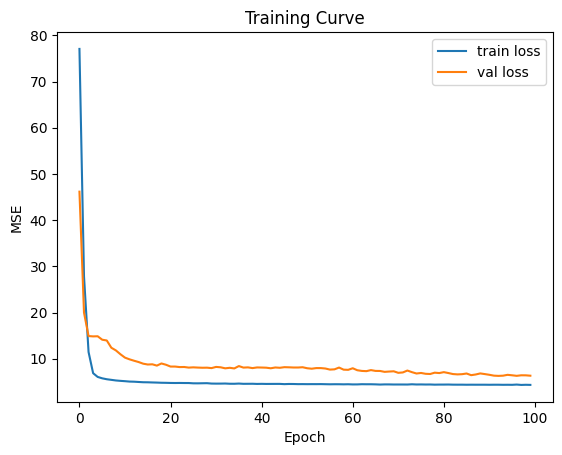

In [9]:
# 12. 학습 곡선 시각화
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.title("Training Curve")
plt.show()

In [10]:
# 13. 테스트 데이터 예측
y_pred = model.predict(X_test).flatten()

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [11]:
# 14. 성능 평가
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE  =", mae)
print("RMSE =", rmse)
print("R2   =", r2)

MAE  = 1.5073026418685913
RMSE = 2.0695688891561184
R2   = 0.6158031225204468


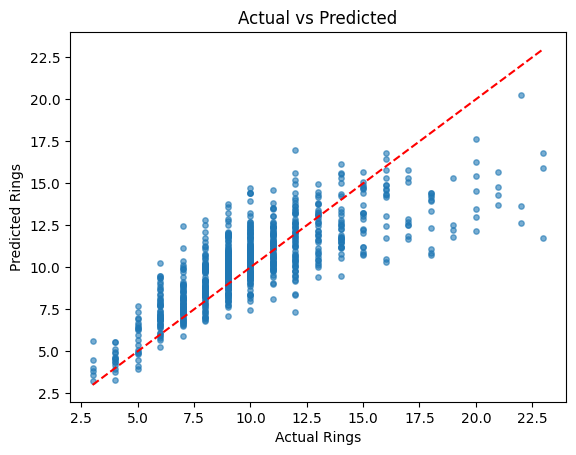

In [12]:
# 15. 실제값 vs 예측값 시각화
plt.scatter(y_test, y_pred, s=15, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")  # 완벽 예측선
plt.xlabel("Actual Rings")
plt.ylabel("Predicted Rings")
plt.title("Actual vs Predicted")
plt.show()